In [50]:
import tensorflow as tf
import gradio as gr
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

In [51]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [52]:
#Exploratory Data Analysis
X_train.shape

(60000, 28, 28)

In [53]:
X_test.shape

(10000, 28, 28)

In [54]:
singleImage = X_train[0]
singleImage

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170,
        253, 253, 253, 253, 253, 225, 172, 253, 242, 195,  64,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  49, 238, 253, 253, 253, 253,
        253, 253, 253, 253, 251,  93,  82,  82,  56,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  18, 219, 253, 253, 253, 253,
        253, 198, 182, 247, 241,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  80, 156, 107, 253, 253,
        205,  11,   0,  43, 154,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  14,   1, 154, 253,
         90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 139, 253,
        190,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  11, 190,
        253,  70,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  35,
        241, 225, 160, 108,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         81, 240, 253, 253, 119,  25,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  45, 186, 253, 253, 150,  27,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  16,  93, 252, 253, 187,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 249, 253, 249,  64,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  46, 130, 183, 253, 253, 207,   2,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  39,
        148, 229, 253, 253, 253, 250, 182,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  24, 114, 221,
        253, 253, 253, 253, 201,  78,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  23,  66, 213, 253, 253,
        253, 253, 198,  81,   2,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  18, 171, 219, 253, 253, 253, 253,
        195,  80,   9,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  55, 172, 226, 253, 253, 253, 253, 244, 133,
         11,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 136, 253, 25

In [55]:
singleImage.min()

np.uint8(0)

In [56]:
singleImage.max()

np.uint8(255)

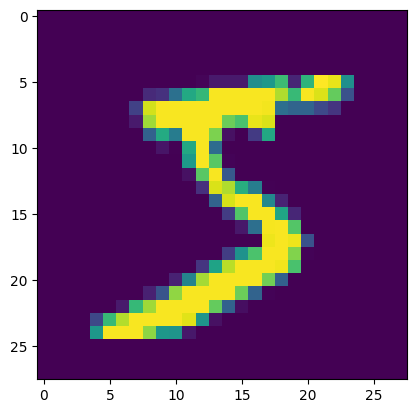

In [57]:
plt.imshow(singleImage)

In [58]:
y_train.shape

(60000,)

In [59]:
y_test.shape

(10000,)

In [60]:
y_train[0]

np.uint8(5)

In [61]:
#Data Preprocessing
y_train_categorical = to_categorical(y_train)
y_train_categorical

array([[0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.]])

In [62]:
y_train_categorical[0]

array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])

In [63]:
y_test_categorical = to_categorical(y_test)
y_test_categorical

array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [64]:
#Normailize Data
X_train = X_train/255
X_test = X_test/255

In [65]:
X_train.max()

np.float64(1.0)

In [66]:
X_train.min()

np.float64(0.0)

In [67]:
X_test.max()

np.float64(1.0)

In [68]:
X_test.min()

np.float64(0.0)

In [69]:
X_train = X_train.reshape(60000, 28, 28, 1)
X_test = X_test.reshape(10000, 28, 28, 1)

In [70]:
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, 4, input_shape = (28, 28, 1), activation = 'relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation = 'relu'),
    tf.keras.layers.Dense(10, activation = 'softmax')
])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 25, 25, 32)     │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,786 (2.26 MB)

 Trainable params: 591,786 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

In [71]:
model.compile(optimizer= 'adam', loss= 'categorical_crossentropy', metrics= ['accuracy'])

In [72]:
history = model.fit(X_train, y_train_categorical, epochs= 7)

Epoch 1/7
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.9587 - loss: 0.1396
Epoch 2/7
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9860 - loss: 0.0456
Epoch 3/7
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9907 - loss: 0.0292
Epoch 4/7
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9939 - loss: 0.0193
Epoch 5/7
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9954 - loss: 0.0141
Epoch 6/7
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9963 - loss: 0.0103
Epoch 7/7
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9972 - loss: 0.0079


In [73]:
loss, accuracy = model.evaluate(X_test, y_test_categorical)
accuracy, loss

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9894 - loss: 0.0376


(0.9894000291824341, 0.03757529705762863)

<Axes: >

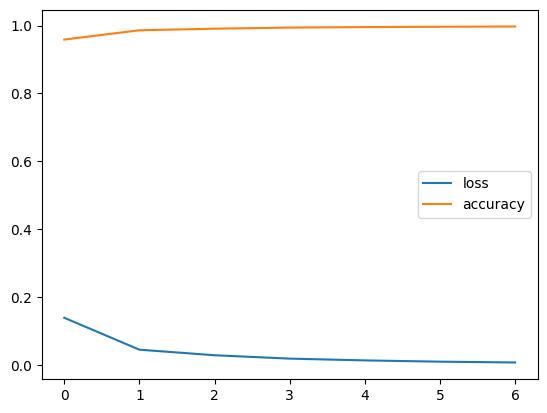

In [74]:
metrics = pd.DataFrame(history.history)
metrics[['loss', 'accuracy']].plot()

In [75]:
prediction = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [76]:
prediction.shape

(10000, 10)

In [77]:
prediction[0]

array([1.9684834e-11, 6.5065917e-12, 4.3899059e-10, 2.5131792e-08,
       2.3482227e-11, 1.7715153e-10, 1.8046830e-16, 1.0000000e+00,
       1.5952109e-09, 2.5481492e-08], dtype=float32)

In [78]:
pred_class = np.argmax(prediction, axis= 1)
pred_class

array([7, 2, 1, ..., 4, 5, 6])

In [79]:
pred_class[0]

np.int64(7)

In [80]:
con_matrix = confusion_matrix(y_test, pred_class)
con_matrix

array([[ 972,    1,    1,    1,    0,    2,    3,    0,    0,    0],
       [   0, 1132,    0,    0,    1,    0,    1,    0,    1,    0],
       [   0,    2, 1016,    2,    0,    0,    2,   10,    0,    0],
       [   0,    0,    0, 1003,    0,    4,    0,    1,    2,    0],
       [   0,    0,    0,    0,  974,    0,    2,    0,    0,    6],
       [   0,    1,    0,    5,    0,  885,    1,    0,    0,    0],
       [   1,    2,    0,    0,    1,    3,  949,    0,    2,    0],
       [   0,    1,    3,    1,    0,    0,    0, 1021,    0,    2],
       [   3,    1,    1,    0,    0,    2,    2,    3,  960,    2],
       [   0,    1,    0,    2,    9,    5,    0,    7,    3,  982]])

In [81]:
class_report = classification_report(y_test, pred_class)
class_report

'              precision    recall  f1-score   support\n\n           0       1.00      0.99      0.99       980\n           1       0.99      1.00      0.99      1135\n           2       1.00      0.98      0.99      1032\n           3       0.99      0.99      0.99      1010\n           4       0.99      0.99      0.99       982\n           5       0.98      0.99      0.99       892\n           6       0.99      0.99      0.99       958\n           7       0.98      0.99      0.99      1028\n           8       0.99      0.99      0.99       974\n           9       0.99      0.97      0.98      1009\n\n    accuracy                           0.99     10000\n   macro avg       0.99      0.99      0.99     10000\nweighted avg       0.99      0.99      0.99     10000\n'

In [82]:
!pip install gradio

In [83]:
!pip show gradio

Name: gradio
Version: 6.29.0
Summary: Python library for easily interacting with trained machine learning models
Home-page: https://github.com/gradio-app/gradio
Author: 
Author-email: Abubakar Abid <gradio-team@huggingface.co>, Ali Abid <gradio-team@huggingface.co>, Ali Abdalla <gradio-team@huggingface.co>, Dawood Khan <gradio-team@huggingface.co>, Ahsen Khaliq <gradio-team@huggingface.co>, Pete Allen <gradio-team@huggingface.co>, Ömer Faruk Özdemir <gradio-team@huggingface.co>, Freddy A Boulton <gradio-team@huggingface.co>, Hannah Blair <gradio-team@huggingface.co>
License: 
Location: /usr/local/lib/python3.13/dist-packages
Requires: anyio, audioop-lts, brotli, fastapi, gradio-client, groovy, hf-gradio, httpx, huggingface-hub, jinja2, markupsafe, numpy, orjson, packaging, pandas, pillow, pydantic, pydub, python-multipart, pytz, pyyaml, safehttpx, semantic-version, starlette, tomlkit, typer, typing-extensions, uvicorn
Required-by: 


In [84]:
model.save("mnist_model.keras")

In [85]:
model = tf.keras.models.load_model("mnist_model.keras")

In [86]:
def predict_digit(image):
  image = image.convert("L").resize((28,28))
  img = np.array(image).astype('float32') / 255
  img = img.reshape(1, 28, 28, 1)
  prediction = model.predict(img, verbose=0)[0]
  return {str(i): float(prediction[i]) for i in range(10)}

In [87]:
demo = gr.Interface(
    fn=predict_digit,
    inputs=gr.Image(type="pil", label="Upload a handwritten digit"),
    outputs=gr.Label(num_top_classes=10, label="Prediction"),
    title="MNIST Digit Recognition",
    description="Upload an image of a handwritten digit (0–9)."
)

In [88]:
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://70d73516c78dfdb285.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
